# Baselines

In this notebook I run the three baselines and look at how propagation affects the IoU. The first baseline runs segmentation on every frame. The other two run it only on every N-th frame and in between either hold the last mask or move it with optical flow.

In [1]:
import os

import cv2
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

import pipeline as p

INTERVALS = [2, 5, 10, 20]
RESULTS_PATH = "results/baselines.pkl"
RUN_BASELINES = False

## Running the baselines

I run every baseline on the 12 development sequences, in total 5,027 frames. The frames are processed one after another. For every frame I store the intersection and union with the annotated mask, the processing time and the mask itself in rle format.

In [2]:
if RUN_BASELINES:
    from ultralytics import YOLO

    frames = p.load_frames(p.DEV_SEQS)
    model = YOLO("yolo26m-seg.pt", task="segment")
    p.segment(model, cv2.imread(frames["image_path"].iloc[0]))  # warm-up, so the first timed frame is not an outlier

    configs = [("every_frame", 1, None)]
    configs += [("hold", n, None) for n in INTERVALS]
    configs += [("flow", n, p.flow_warp) for n in INTERVALS]

    runs = []
    for method, interval, propagate in configs:
        for _, seq_frames in frames.groupby("seq"):
            run = p.run_sequence(seq_frames, model, interval, propagate)
            run.insert(0, "interval", interval)
            run.insert(0, "method", method)
            runs.append(run)

    os.makedirs("results", exist_ok=True)
    pd.concat(runs, ignore_index=True).to_pickle(RESULTS_PATH)

results = pd.read_pickle(RESULTS_PATH)

## Results

The IoU is computed over all frames together (sum of intersections divided by sum of unions). The times are means in milliseconds. "late" is the share of frames that took longer than the 100 ms frame period.

The 100ms constraint are comming from constraint that original video was filmed at 10 FPS, so one frame was 100ms long. If the processing would take more then 100ms, then it would mean that in real-time inference the mask would stale and arrive late.

In [3]:
summary = results.groupby(["method", "interval"], sort=False).apply(p.summarize, include_groups=False)
summary.round(3)

iou  segment_ms  propagate_ms  mean_ms  late  \
method      interval                                                   
every_frame 1         0.895      15.742           NaN   15.742   0.0   
hold        2         0.800      18.503         0.001    9.265   0.0   
            5         0.620      35.997         0.001    7.233   0.0   
            10        0.498      58.491         0.001    5.911   0.0   
            20        0.395      79.885         0.001    4.069   0.0   
flow        2         0.882      42.938        45.124   44.030   0.0   
            5         0.837      80.269        45.563   52.536   0.0   
            10        0.767      85.433        44.131   48.305   0.0   
            20        0.656      87.520        42.456   44.751   0.0   

                      segment_calls  
method      interval                 
every_frame 1                5027.0  
hold        2                2517.0  
            5                1010.0  
            10                508.0  
            20                256.0  
flow        2                2517.0  
            5                1010.0  
            10                508.0  
            20                256.0

## How propagation affects IoU

In [4]:
LABELS = {"every_frame": "segmentation every frame", "hold": "hold last mask", "flow": "optical-flow propagation"}
COLOURS = {"hold": "#2a78d6", "flow": "#eb6834"}


def pooled_iou(d):
    return d["intersection"].sum() / d["union"].sum()


def plot_iou(series, xlabel, title):
    fig, ax = plt.subplots(figsize=(7, 4))
    for method, s in series.items():
        ax.plot(s.index, s.values, color=COLOURS[method], linewidth=2, marker="o", markersize=5, label=LABELS[method])
        ax.annotate(f"{s.values[-1]:.2f}", (s.index[-1], s.values[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", color="#52514e")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("IoU")
    ax.set_ylim(0, 1)
    ax.set_title(title, loc="left")
    ax.legend(frameon=False, loc="lower left")
    return ax

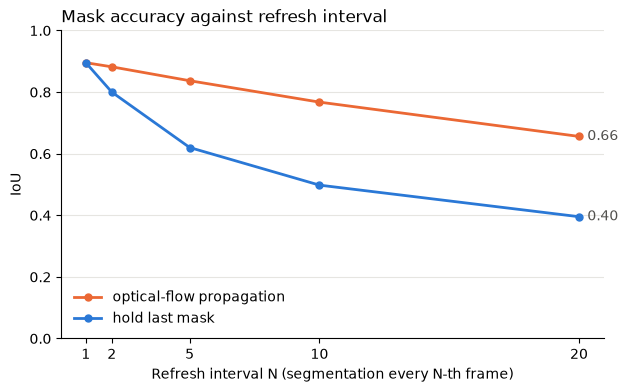

In [5]:
iou = results.groupby(["method", "interval"]).apply(pooled_iou, include_groups=False)
ax = plot_iou({m: pd.concat([iou["every_frame"], iou[m]]) for m in ["flow", "hold"]},
              "Refresh interval N (segmentation every N-th frame)", "Mask accuracy against refresh interval")
ax.set_xticks([1] + INTERVALS);

With segmentation on every frame I get an IoU of 0.895, which is the best this model can do on the data. When I segment only every N-th frame and hold the last mask, the IoU drops quickly, to 0.62 at N = 5 and 0.40 at N = 20. With optical flow the mask follows the objects and the drop is much smaller, 0.84 at N = 5 and 0.66 at N = 20. So flow wins back about 80% of the lost accuracy at N = 5 and about half of it at N = 20.

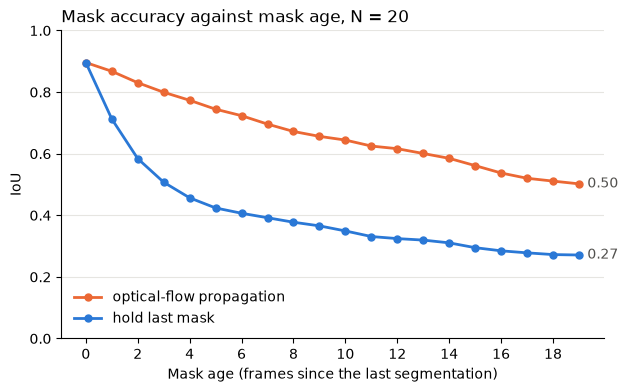

In [6]:
AGE_INTERVAL = 20
iou_by_age = results[results["interval"] == AGE_INTERVAL].groupby(["method", "mask_age"]).apply(pooled_iou, include_groups=False)
ax = plot_iou({m: iou_by_age[m] for m in ["flow", "hold"]},
              "Mask age (frames since the last segmentation)", f"Mask accuracy against mask age, N = {AGE_INTERVAL}")
ax.set_xticks(range(0, AGE_INTERVAL, 2));

This plot looks inside one refresh interval (N = 20). A held mask loses most of its accuracy in the first four frames, from 0.90 to 0.46. A propagated mask gets worse slowly and almost linearly, and is still at 0.50 after 19 frames.

## Mask overlays

Here I show the same frames for all three baselines. I take frames just before a refresh (N = 10, mask age 9), because this is where holding and propagating differ most. The frames are drawn at random with a fixed seed.

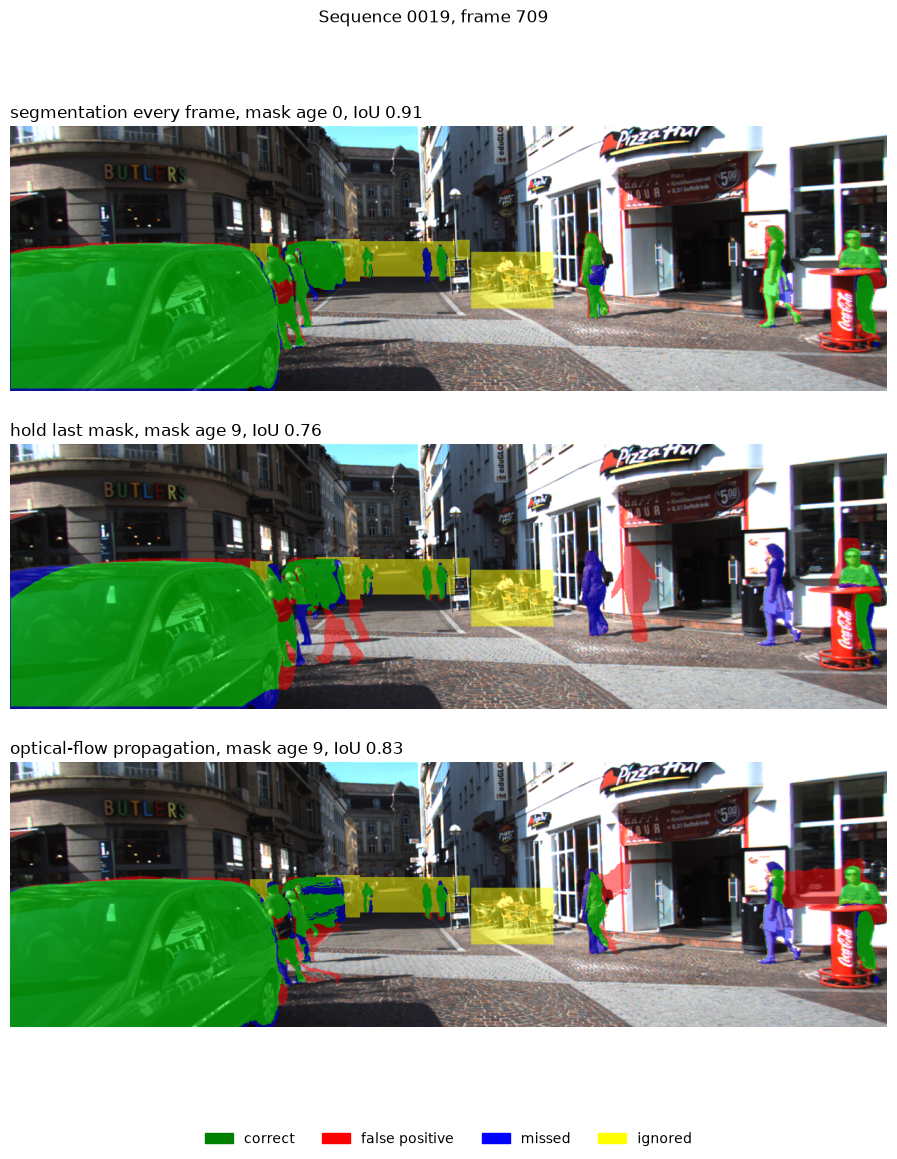

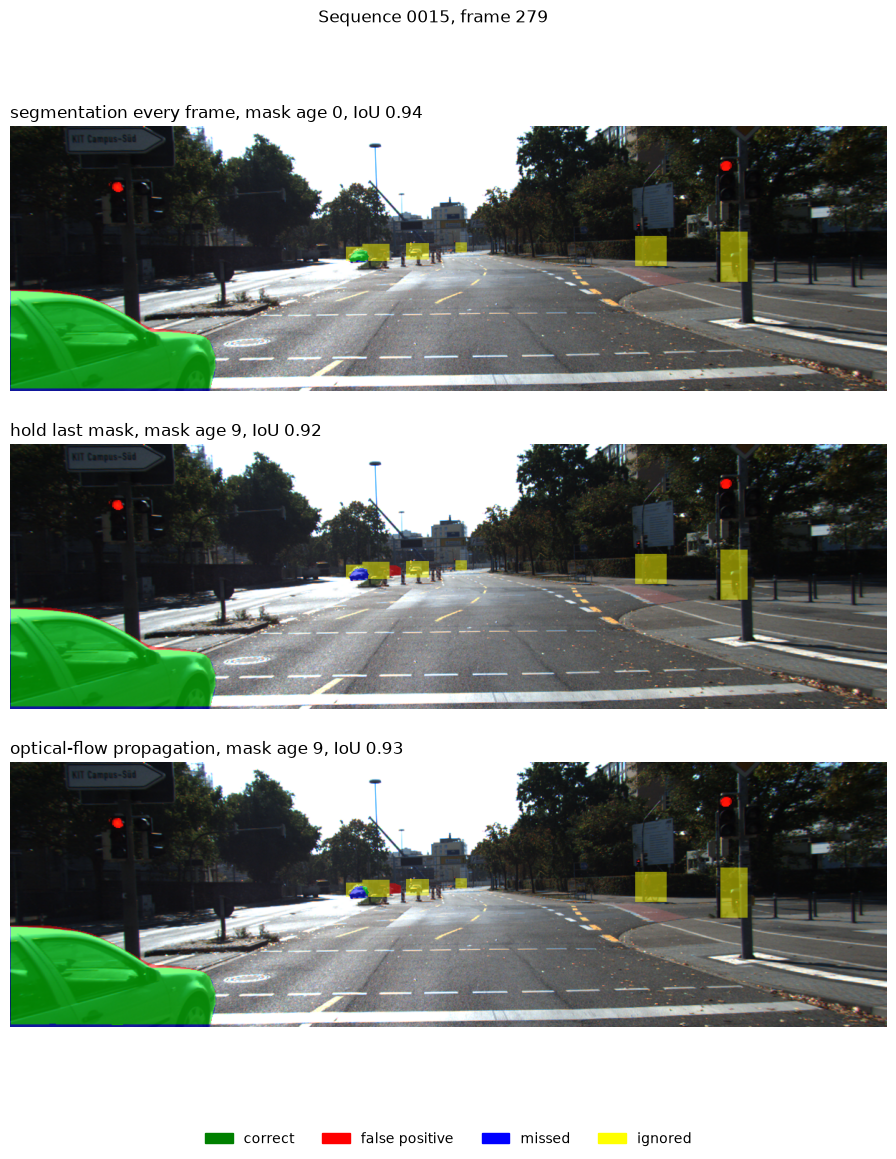

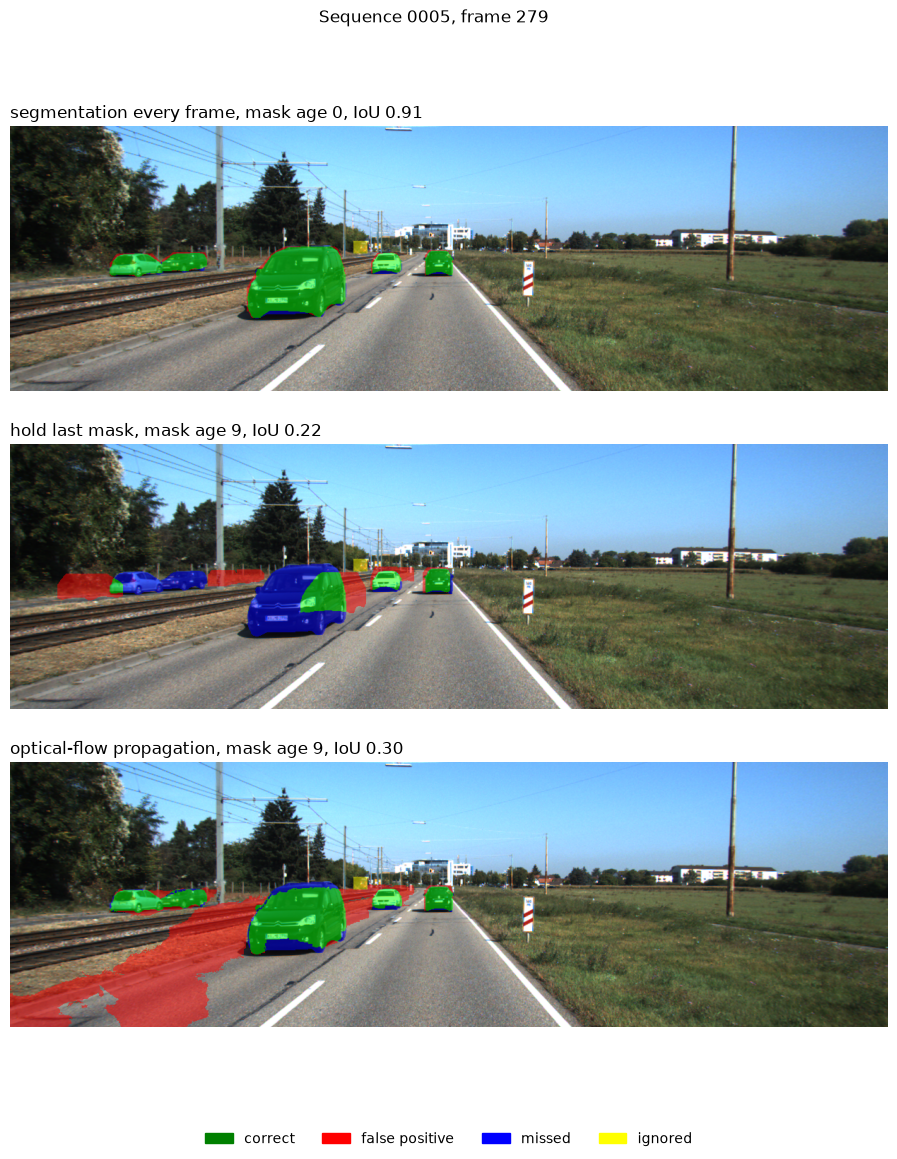

In [7]:
OVERLAY_INTERVAL = 10


def show_overlays(frame):
    img = cv2.imread(frame.image_path)
    shape = img.shape[:2]
    gt, ignore = p.to_mask(frame.gt_object, shape), p.to_mask(frame.ignore_object, shape)

    configs = [("every_frame", 1), ("hold", OVERLAY_INTERVAL), ("flow", OVERLAY_INTERVAL)]
    fig, axes = plt.subplots(len(configs), 1, figsize=(12, 3.9 * len(configs)))
    for ax, (method, interval) in zip(axes, configs):
        row = results[(results["method"] == method) & (results["interval"] == interval)
                      & (results["seq"] == frame.seq) & (results["time_frame"] == frame.time_frame)].iloc[0]
        overlay = p.error_overlay(img, p.to_mask(row["pred_rle"], shape), gt, ignore)
        ax.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{LABELS[method]}, mask age {row['mask_age']}, IoU {row['intersection'] / row['union']:.2f}", loc="left")
        ax.axis("off")
    fig.suptitle(f"Sequence {frame.seq}, frame {frame.time_frame}")
    fig.legend(
        handles=[Patch(color="green", label="correct"),
                 Patch(color="red", label="false positive"),
                 Patch(color="blue", label="missed"),
                 Patch(color="yellow", label="ignored")],
        loc="lower center", ncol=4, frameon=False,
    )


hold = results[(results["method"] == "hold") & (results["interval"] == OVERLAY_INTERVAL)]
stale = hold[(hold["mask_age"] == OVERLAY_INTERVAL - 1) & (hold["union"] > 2000)]
chosen = stale.sample(3, random_state=0)[p.KEYS].merge(p.load_frames(p.DEV_SEQS), on=p.KEYS)
for frame in chosen.itertuples():
    show_overlays(frame)

In the held mask the objects have moved away, so there is a red band where the object was and a blue one where it is now. Flow moves the mask with the objects and fixes most of this.

Flow also makes its own mistakes. In sequence 0005 the mask of a moving car is smeared over the road behind it. The road that becomes visible has no match in the previous frame, so the flow there is wrong, and the error adds up with every warp.

## Processing time

Segmentation runs on the GPU (YOLO26m-seg on an RTX 4060 Laptop GPU) and optical flow on the CPU, because in the final setting the client is a weak device without a GPU.

On my laptop flow is not cheaper than segmentation. One flow step takes about 45 ms on the CPU and one segmentation about 16 ms on the GPU. What flow saves is segmentation calls, 1,010 instead of 5,027 at N = 5, and this is what matters once the segmenter runs on a server. All frames were processed within the 100 ms frame period.

The time of one segmentation call grows when calls are sparse (15.7 ms every frame, about 80 ms at N = 20). I suppose it's connected somehow to how memory and GPU works.